# Renewables Ninja ; Wind Power Generation Analysis

This notebook fetches real hourly wind power generation data for 
Nicosia, Cyprus using the Renewables Ninja API ; powered by NASA 
MERRA2 reanalysis data.

**What this notebook does:**
- Authenticates with the Renewables Ninja API using a secure token
- Fetches hourly wind generation data for a full year (2020)
- Loads the data into a pandas DataFrame for analysis
- Plots hourly wind electricity output

**The goal simplified:**
Asking Renewables Ninja ; "how much electricity would a 1MW Vestas V80 
wind turbine generate, hour by hour, for an entire year, at Nicosia, Cyprus?"

**Why wind data matters:**
Solar generation is predictable ; it follows the sun. Wind generation 
is less predictable ; it depends on weather patterns. Understanding 
both is essential before deciding which technology ; or combination 
of both ; is most suitable for a given location.

---


## Step 1 : Setup

Loading all required libraries and reading the API token 
securely from the .env file. Same setup as Notebook 1.

---

In [7]:
import requests
import json
import io
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
from geopy.geocoders import Nominatim
from dotenv import load_dotenv
import os

# Load token
load_dotenv()
token = os.getenv("NINJA_TOKEN")
print("Token loaded successfully:", token is not None)

# Location ; hardcoded to avoid input() breaking Run All
place = "Nicosia, Cyprus"
geolocator = Nominatim(user_agent="renewables_ninja_app")
information = geolocator.geocode(place)
lat = information[1][0]
lon = information[1][1]

print(f"Location : {place}")
print(f"Latitude : {lat}")
print(f"Longitude : {lon}")

Token loaded successfully: True
Location : Nicosia, Cyprus
Latitude : 35.1746503
Longitude : 33.3638783


---
## Step 2 : Fetch Wind Data

I configured a 1MW Vestas V80 2000 wind turbine at Nicosia, Cyprus 
and called the Renewables Ninja API to fetch hourly generation 
data for the full year 2020.

**Turbine configuration:**
- Capacity : 1000 kW (1 MW)
- Hub height : 100m ; typical for modern onshore wind turbines
- Turbine model : Vestas V80 2000 ; a widely deployed onshore turbine
- Dataset : NASA MERRA2

---

In [8]:
# API base URL
api_base = "https://www.renewables.ninja/api/"
url_wind = api_base + "data/wind"

# Wind turbine parameters
args_wind = {
    "lat": lat,
    "lon": lon,
    "date_from": "2020-01-01",
    "date_to": "2020-12-31",
    "capacity": 1000,
    "height": 100,
    "turbine": "Vestas V80 2000",
    "format": "json",
    "local_time": "true",
    "raw": "true"
}

# Authenticate and fetch
session = requests.session()
session.headers = {"Authorization": "Token " + token}

print("Fetching wind data...")
response_wind = session.get(url_wind, params=args_wind)
print(f"Status code : {response_wind.status_code}")

Fetching wind data...
Status code : 200


In [9]:
# Parse JSON response
parsed_wind = json.loads(response_wind.text)

# Extract metadata and data
metadata_wind = parsed_wind["metadata"]
data_wind = pd.read_json(
    io.StringIO(json.dumps(parsed_wind["data"])),
    orient="index"
)

# Confirm what we got
print("Metadata:")
print(metadata_wind)
print(f"\nData shape : {data_wind.shape}")
print(f"Columns : {list(data_wind.columns)}")
data_wind.head()

Metadata:
{'units': {'time': 'UTC', 'local_time': 'Europe/Athens', 'electricity': 'kW', 'wind_speed': 'm/s'}, 'params': {'lat': '35.1746503', 'lon': '33.3638783', 'date_from': '2020-01-01', 'date_to': '2020-12-31', 'capacity': '1000', 'height': '100', 'turbine': 'Vestas V80 2000', 'local_time': 'true', 'raw': 'true'}}

Data shape : (8784, 3)
Columns : ['local_time', 'electricity', 'wind_speed']


,local_time,electricity,wind_speed
2020-01-01 00:00:00,2020-01-01 02:00:00+02:00,283.566,7.103
2020-01-01 01:00:00,2020-01-01 03:00:00+02:00,263.369,6.919
2020-01-01 02:00:00,2020-01-01 04:00:00+02:00,238.016,6.684
2020-01-01 03:00:00,2020-01-01 05:00:00+02:00,192.317,6.221
2020-01-01 04:00:00,2020-01-01 06:00:00+02:00,155.671,5.793


---

**First observation:**

Unlike solar, the wind turbine is already generating 283 kW at midnight 
on 1st January. Wind generation is not dependent on sunlight ; it 
operates at any hour as long as wind speed is sufficient.

This highlights a key difference between the two technologies:
- Solar generation follows a predictable daily cycle ; zero at night, 
  peak at midday
- Wind generation follows weather patterns ; it can generate at any 
  hour but is less predictable

This is why combining solar and wind ; or pairing either with battery 
storage ; is more reliable than relying on a single technology alone.

---


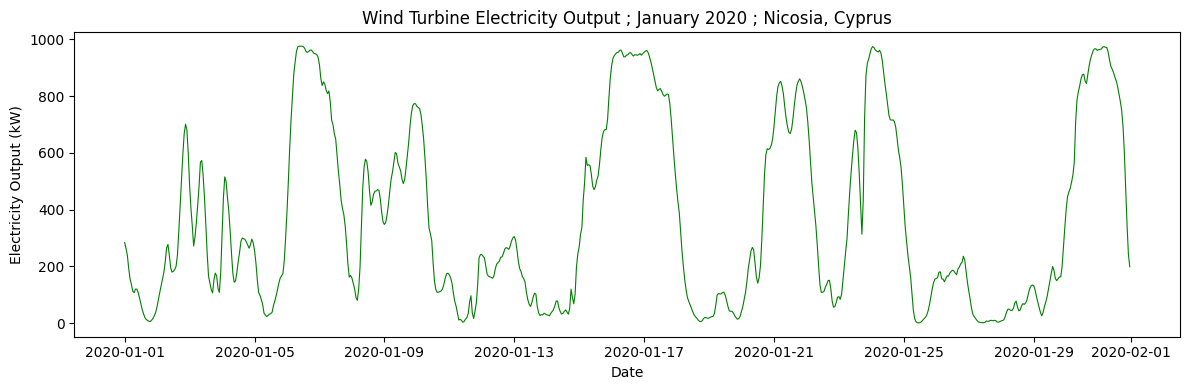

In [10]:
# Plot wind electricity output for January
january_wind = data_wind[data_wind.index < "2020-02-01"]

plt.figure(figsize=(12, 4))
plt.plot(january_wind.index, january_wind["electricity"],
         color="green", linewidth=0.8)
plt.title(f"Wind Turbine Electricity Output ; January 2020 ; {place}")
plt.xlabel("Date")
plt.ylabel("Electricity Output (kW)")
plt.tight_layout()
plt.show()